## A coin-margined account

An inverse perpetual is quoted in dollars and settled in its coin: its contracts are each
worth a fixed number of dollars, and the account's balance, fees, funding and equity are
all counted in bitcoin. Binance's BTCUSD contract over 2024 and 2025, an account of one
bitcoin, held short and held long, beside holding the coin alone.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import matplotlib.ticker
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 2.0.0, exchange-router 3.0.1


### The bars

The contract's hourly bars with its funding, fetched once into `bars/`. Its instrument
carries the dollars one contract is worth, and the asset the account settles in.

In [2]:
PATH = pathlib.Path("../bars/binance-inverse-btcusd-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="inverse",
                                         interval="1h", symbols=["BTCUSD"],
                                         start="2024-01-01", end="2025-12-31", funding=True)
    data.save(path=PATH)

contract = data.instruments[0]

print(data)
print(f"{contract.symbol}: {contract.contract:g} dollars a contract, settled in "
      f"{contract.settlement}, quoted in {contract.quote}")

Data(BTCUSD, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00)
BTCUSD: 100 dollars a contract, settled in BTC, quoted in USD


### Short and long

`binance_inverse` with a balance of one bitcoin. A weight is the contracts' value in the
coin over the equity, so a short of one holds the account's dollar value still, and a long
of one doubles its exposure to the price. A rebalance under 5% of the account is left
undone.

In [3]:
venue = probatum.venues.binance_inverse.replace(balance=1.0)

runs = {side: probatum.backtest(numpy.full(shape=len(data), fill_value=weight), data=data,
                                venue=venue, tolerance=0.05)
        for side, weight in {"short 1x": -1.0, "long 1x": 1.0}.items()}

runs["short 1x"]

,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,-41.73,41.14,-81.95,103.71,0.95,"studentized stationary block bootstrap, blocks of 141.2 bars",
cagr_pct,-23.64,18.77,-57.46,42.66,0.95,"studentized stationary block bootstrap, blocks of 141.2 bars",
volatility_pct,47.79,23.70,44.34,52.08,0.95,"studentized stationary block bootstrap, blocks of 141.2 bars",
sharpe,-0.33,0.84,-1.71,1.06,0.95,"delta method, Newey-West lag 11, floored at lag zero",
max_drawdown_pct,63.44,21.87,35.30,86.40,0.95,"middle of resampled histories, stationary block bootstrap, blocks of 141.2 bars",
exposure_pct,100.00,,,,,,
num_trades,0,,,,,,
win_rate,,,,,,,1
profit_factor,,,,,,,1
costs,-0.107,,,,,,


### Equity in the coin and in dollars

The ledger keeps the equity in the coin and, at each close, its value in dollars. Holding
the coin alone is the cash baseline: one bitcoin on every row.

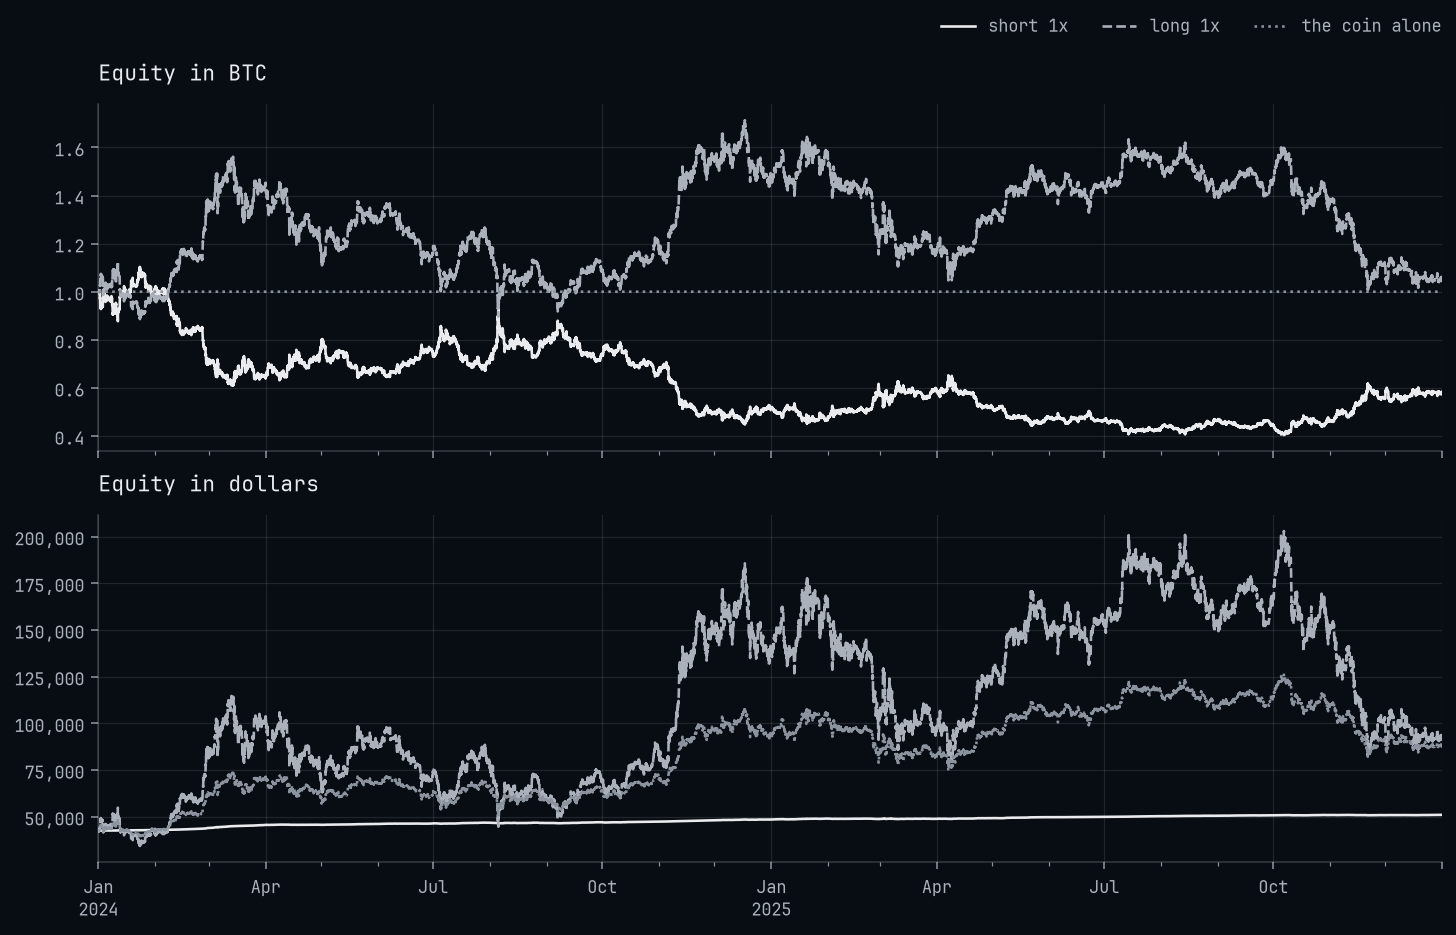

In [4]:
ledgers = {side: run.ledger.to_pandas().set_index(keys="time") for side, run in runs.items()}
close   = pandas.Series(data.close, index=pandas.to_datetime(data.time, utc=True))

coin    = pandas.DataFrame({side: ledger["equity"] for side, ledger in ledgers.items()})
dollars = pandas.DataFrame({side: ledger["equity_in_quote"]
                            for side, ledger in ledgers.items()})

coin["the coin alone"]    = 1.0
dollars["the coin alone"] = close

figure, (top, bottom) = matplotlib.pyplot.subplots(nrows=2, sharex=True,
                                                   figsize=(10.0, 6.4))
coin.plot(ax=top, title="Equity in BTC", xlabel="", legend=False)
dollars.plot(ax=bottom, title="Equity in dollars", xlabel="", legend=False)
bottom.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter(fmt="{x:,.0f}"))

handles, labels = top.get_legend_handles_labels()
figure.legend(handles=handles, labels=labels, loc="outside upper right", ncols=3)
matplotlib.pyplot.show()

### What each paid, in the coin

Fees and funding are charged in bitcoin, each its rate of the notional valued in the coin.

In [5]:
pandas.DataFrame({side: {"equity, BTC": run.equity[-1], **run.costs}
                  for side, run in runs.items()}).T.round(decimals=6)

,"equity, BTC",fees,funding,spread,slippage,impact,liquidation,dust
short 1x,0.582741,0.000546,-0.107719,0.00000,0.000109,0.000000,0.0,0.0
long 1x,1.045298,0.019936,0.229517,0.00165,0.003886,0.000174,0.0,0.0
